<a href="https://colab.research.google.com/github/Seraphim-Vasilis-Partsakoulakis/credit-default-risk-modeling/blob/main/credit_default_risk_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = 'https://raw.githubusercontent.com/fkottas/Teaching-Courses/main/Machine%20Learning%20in%20Finance/2026-2027/lectures/lecture-00-01/data/credit/default_of_credit_card_clients.csv.gz'

credit = pd.read_csv(DATA_URL, compression='gzip')

credit = credit.rename(columns={'default payment next month': 'default_next_month'})

credit.head(3)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


1. Sourse, access date, observation unit, target and units


In [ ]:
# @title
print("""* Source: UCI Machine Learning Repository (Dataset 350)
* Access Date: 25 October 2026
* Observation Unit: One individual credit card account / borrower
* Target: default_next_month (1 = default, 0 = no default)
* Units: New Taiwan Dollars (NT$)""")

* Source: UCI Machine Learning Repository (Dataset 350)
* Access Date: 25 October 2026
* Observation Unit: One individual credit card account / borrower
* Target: default_next_month (1 = default, 0 = no default)
* Units: New Taiwan Dollars (NT$)


2) Audit in Shape, data types, missingness, duplicate rows, and target balance.

In [ ]:
# @title
rows, cols = credit.shape
print(f"1. Dataset dimensions: {rows:,} rows and {cols} columns")

print("\n2. Data types distribution across columns:")
print(credit.dtypes.value_counts())

missing_cells = credit.isna().sum().sum()
print(f"\n3. Total missing cells: {missing_cells}")

duplicates = credit.duplicated().sum()
print(f"4. Duplicate rows: {duplicates}")

print("\n5. Target distribution (default_next_month):")
target_counts = credit['default_next_month'].value_counts()
target_pct = (credit['default_next_month'].value_counts(normalize=True) * 100).round(2)

target_table = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_pct
})
target_table.index = ['No Default (0)', 'Default (1)']
print(target_table)

1. Dataset dimensions: 30,000 rows and 25 columns

2. Data types distribution across columns:
int64    25
Name: count, dtype: int64

3. Total missing cells: 0
4. Duplicate rows: 0

5. Target distribution (default_next_month):
                Count  Percentage (%)
No Default (0)  23364           77.88
Default (1)      6636           22.12


3. Descriptive statisticks(mean, median, std, min, max, etc.) for 6 variables

In [ ]:
# @title
credit.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default_next_month']

In [ ]:
# @title
selected_vars = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_AMT2']

stats = credit[selected_vars].describe().T

stats['IQR'] = stats['75%'] - stats['25%']

stats_summary = stats[['count', 'mean', 'std', 'min', '50%', 'max', 'IQR']].round(1)

print(" DESCRIPTIVE STATISTICS of 6 VARIABLES")
stats_summary

 DESCRIPTIVE STATISTICS of 6 VARIABLES


,count,mean,std,min,50%,max,IQR
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,140000.0,1000000.0,190000.0
SEX,30000.0,1.6,0.5,1.0,2.0,2.0,1.0
EDUCATION,30000.0,1.9,0.8,0.0,2.0,6.0,1.0
MARRIAGE,30000.0,1.6,0.5,0.0,2.0,3.0,1.0
AGE,30000.0,35.5,9.2,21.0,34.0,79.0,13.0
PAY_AMT2,30000.0,5921.2,23040.9,0.0,2009.0,1684259.0,4167.0


4. Groupby by **Education** and **Age** for easier comparison between the creditors

In [ ]:
# @title
grouped_stats = credit.groupby('EDUCATION').agg(
    borrower_count=('default_next_month', 'count'),
    default_rate=('default_next_month', 'mean'),
    median_credit_limit=('LIMIT_BAL', 'median'),
    mean_credit_limit=('LIMIT_BAL', 'mean')
).round(2)
print(" GROUPED ANALYSIS BY EDUCATION ")
grouped_stats[['borrower_count', 'default_rate', 'median_credit_limit', 'mean_credit_limit']]

 GROUPED ANALYSIS BY EDUCATION 


,borrower_count,default_rate,median_credit_limit,mean_credit_limit
EDUCATION,,,,
0,14,0.00,215000.0,217142.86
1,10585,0.19,200000.0,212956.07
2,14030,0.24,110000.0,147062.44
3,4917,0.25,80000.0,126550.27
4,123,0.06,200000.0,220894.31
5,280,0.06,150000.0,168164.29
6,51,0.16,100000.0,148235.29


Appendix: Variable Encoding Dictionary



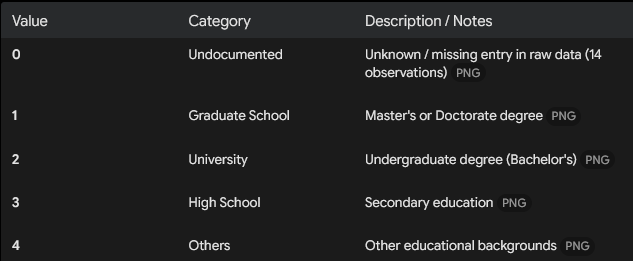

In [ ]:
# @title
age_stats = credit.groupby('AGE').agg(
    borrower_count=('default_next_month', 'count'),
    default_rate=('default_next_month', 'mean'),
    median_credit_limit=('LIMIT_BAL', 'median'),
    mean_credit_limit=('LIMIT_BAL', 'mean')
).round(2)
print("GROUPED ANALYSIS BY EXACT AGE (FIRST 10 ROWS)")
age_stats.head(10)

GROUPED ANALYSIS BY EXACT AGE (FIRST 10 ROWS)


,borrower_count,default_rate,median_credit_limit,mean_credit_limit
AGE,,,,
21,67,0.21,20000.0,23283.58
22,560,0.30,30000.0,37928.57
23,931,0.27,50000.0,59752.95
24,1127,0.27,50000.0,75661.05
25,1186,0.25,80000.0,102731.87
26,1256,0.20,100000.0,128813.69
27,1477,0.21,130000.0,147941.77
28,1409,0.20,150000.0,170943.93
29,1605,0.20,150000.0,179401.87


5. Plots and Interpretations

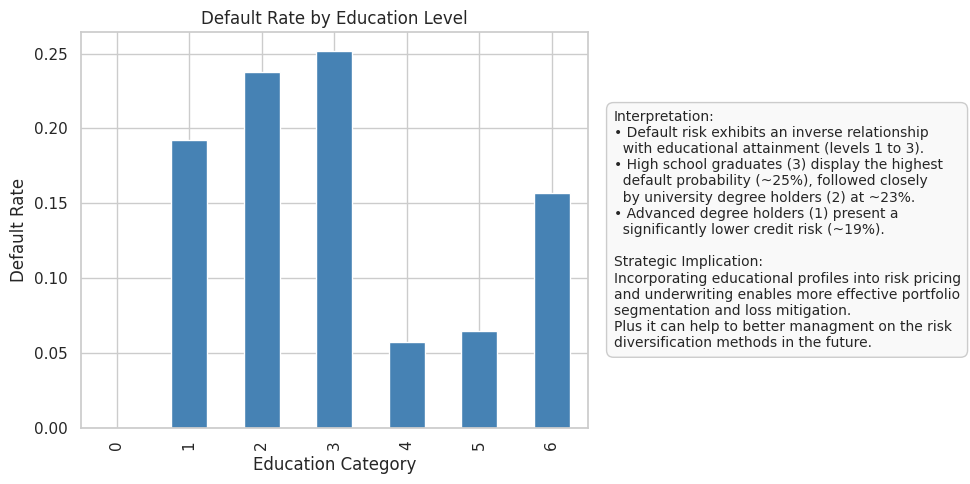

In [ ]:
# @title
import matplotlib.pyplot as plt

edu_default_rate = credit.groupby('EDUCATION')['default_next_month'].mean()

fig, ax = plt.subplots(figsize=(10, 5))
edu_default_rate.plot(kind='bar', color='steelblue', ax=ax)

ax.set_title('Default Rate by Education Level')
ax.set_xlabel('Education Category')
ax.set_ylabel('Default Rate')

desc_text = (
    "Interpretation:\n"
    "• Default risk exhibits an inverse relationship\n"
    "  with educational attainment (levels 1 to 3).\n"
    "• High school graduates (3) display the highest\n"
    "  default probability (~25%), followed closely\n"
    "  by university degree holders (2) at ~23%.\n"
    "• Advanced degree holders (1) present a\n"
    "  significantly lower credit risk (~19%).\n\n"
    "Strategic Implication:\n"
    "Incorporating educational profiles into risk pricing\n"
    "and underwriting enables more effective portfolio\n"
    "segmentation and loss mitigation.\n"
     "Plus it can help to better managment on the risk \n"
      "diversification methods in the future."
)

ax.text(1.05, 0.5, desc_text, transform=ax.transAxes,
        fontsize=10, verticalalignment='center',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f9f9f9', edgecolor='#cccccc'))

plt.tight_layout()
plt.show()

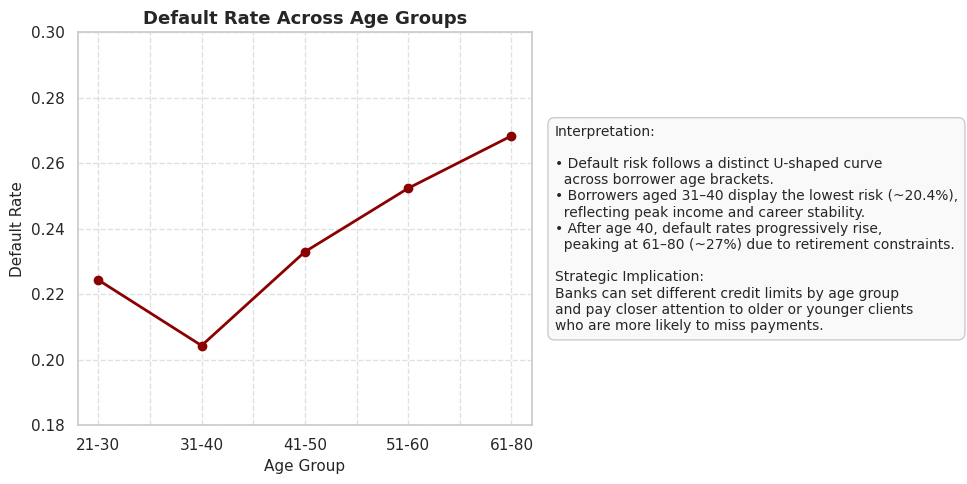

In [ ]:
# @title
import matplotlib.pyplot as plt
import pandas as pd

credit['AGE_GROUP'] = pd.cut(
    credit['AGE'],
    bins=[20, 30, 40, 50, 60, 80],
    labels=['21-30', '31-40', '41-50', '51-60', '61-80']
)

age_default_rate = credit.groupby('AGE_GROUP', observed=False)['default_next_month'].mean()

fig, ax = plt.subplots(figsize=(10, 5))
age_default_rate.plot(kind='line', marker='o', linewidth=2, color='darkred', ax=ax)

ax.set_title('Default Rate Across Age Groups', fontsize=13, weight='bold')
ax.set_xlabel('Age Group', fontsize=11)
ax.set_ylabel('Default Rate', fontsize=11)
ax.set_ylim(0.18, 0.30)
ax.grid(True, linestyle='--', alpha=0.6)

desc_text_age = (
    "Interpretation:\n\n"
    "• Default risk follows a distinct U-shaped curve\n"
    "  across borrower age brackets.\n"
    "• Borrowers aged 31–40 display the lowest risk (~20.4%),\n"
    "  reflecting peak income and career stability.\n"
    "• After age 40, default rates progressively rise,\n"
    "  peaking at 61–80 (~27%) due to retirement constraints.\n\n"
    "Strategic Implication:\n"
    "Banks can set different credit limits by age group\n"
    "and pay closer attention to older or younger clients\n"
    "who are more likely to miss payments."
)

ax.text(1.05, 0.5, desc_text_age, transform=ax.transAxes,
        fontsize=10, verticalalignment='center',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f9f9f9', edgecolor='#cccccc'))

plt.tight_layout()
plt.show()

**Limitations**

A major data-quality limitation we face is the educational attainment feature (EDUCATION). While descriptive patterns emerge, the data lacks in detail and transparency required to deploy a real-world credit score model. As we demonstrated in the 1st diagram and the appendix, the 'Other' and 'Undocumented' categories skip vital customer details, which makes information asymmetry a tremendous problem to deal with. This missing information is critical: as a capital lender, distinguishing whether borrowers hold advanced research degrees (e.g., Ph.D., Post-Doc) or are high-school dropouts is essential for pricing credit risk accurately and refining portfolio risk-minimization models.

**Causality**

In the Age Group diagram, we see that borrowers aged 21–30 and 41+ have higher default rates than those aged 31–40[cite: 4]. However, age itself does not directly cause someone to default.

The main reason is **omitted variable bias**: age simply stands in for missing financial information that truly determines whether someone can pay. For example, the dataset does not include a borrower's actual income, savings, or total wealth - assets and so on. Younger people often have lower salaries in the beginning of their careers and fewer savings overall, while older people may face lower retirement incomes or medical bills. These missing financial factors, not their age, explain in a way the higher default rates.